# Tarea 1 – Parte 1: Recolección, limpieza y EDA

**Pregunta guía:** ¿Pueden convertirse titulares peruanos en un clasificador de noticias?

| Campo | Valor |
|---|---|
| Fecha de descarga | 2026-10-18 (se registra también automáticamente en la celda siguiente) |
| Opción elegida | **C – Comparada** (La República + El Comercio) |
| URL base La República | https://larepublica.pe |
| URL base El Comercio | https://elcomercio.pe |
| Categorías finales | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |

### Estrategia de recolección y respeto a los medios
* Se leyó el `robots.txt` de ambos medios (respaldado en `datos/raw/`). Ambos **permiten** `/rss/` y `/sitemap/` y declaran sus feeds oficiales.
* **La República** prohíbe la paginación (`Disallow: /*/pag/`), así que **no** se recorren páginas antiguas. Se combinan sus canales oficiales: RSS por sección + RSS `home.xml`, sitemaps `/sitemap/web/*.xml` y la portada de cada sección (sin paginar).
* **El Comercio** publica sitemaps por sección (`/sitemap/web/<seccion>/?outputType=xml`, ~100 URLs c/u) y feeds RSS de Google News. Sus RSS antiguos `/arcio/rss/` responden 301 (descontinuados), por eso se usan los sitemaps.
* Cada URL de artículo se valida contra las reglas `Disallow` del `robots.txt` antes de descargarla.
* `User-Agent` descriptivo, **pausa de 1.5 s** entre solicitudes y **máximo 1 reintento**.
* Todo lo descargado (robots, RSS, sitemaps, portadas) se guarda en `datos/raw/` y la metadata de artículos en `datos/raw/articulos_raw.jsonl`. Al re-ejecutar el notebook se reutiliza ese respaldo: no se repiten descargas, el resultado es reproducible y el scraping no "se cae" si el sitio cambia o bloquea después. Para una descarga nueva basta con vaciar `datos/raw/`.

In [1]:
import re, json, time, html
from datetime import datetime
from pathlib import Path
from urllib.parse import urlparse, urlunparse

import requests
import pandas as pd
from bs4 import BeautifulSoup
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+png"  # interactivo en Jupyter/VS Code + imagen estática visible en GitHub
pd.set_option("display.max_colwidth", 120)

RAW = Path("datos/raw"); RAW.mkdir(parents=True, exist_ok=True)
CACHE = RAW / "articulos_raw.jsonl"
FECHA_DESCARGA = datetime.now().strftime("%Y-%m-%d %H:%M")
HEADERS = {"User-Agent": "TareaPUCP-ClasificadorNoticias/1.0 (proyecto academico, curso Python Intermedio; scraping educativo con pausas)"}
PAUSA = 1.5      # segundos entre solicitudes
REINTENTOS = 1   # máximo 1 reintento

session = requests.Session()
session.headers.update(HEADERS)
print("Fecha de ejecución:", FECHA_DESCARGA)

Fecha de ejecución: 2026-10-18 19:28


## 1. Descarga respetuosa y lectura de `robots.txt`

In [2]:
def descargar(url):
    "GET con pausa fija y como máximo 1 reintento. Devuelve el texto o None."
    for intento in range(REINTENTOS + 1):
        try:
            r = session.get(url, timeout=25)
            time.sleep(PAUSA)
            if r.status_code == 200:
                return r.text
            print(f"  HTTP {r.status_code} (intento {intento + 1}): {url}")
        except requests.RequestException as e:
            print(f"  {type(e).__name__} (intento {intento + 1}): {url}")
            time.sleep(PAUSA)
    return None


def slug(url):
    return re.sub(r"[^a-z0-9]+", "_", url.lower().split("//", 1)[1]).strip("_")[:120]


def leer_o_descargar(url, ext):
    "Usa el respaldo crudo de datos/raw/ si existe; si no, descarga y lo guarda."
    p = RAW / f"{slug(url)}.{ext}"
    if p.exists():
        return p.read_text(encoding="utf-8")
    txt = descargar(url)
    if txt is not None:
        p.write_text(txt, encoding="utf-8")
    return txt


def reglas_robots(base):
    "Reglas Disallow/Allow que aplican al grupo 'User-agent: *', convertidas a regex."
    txt = leer_o_descargar(base + "/robots.txt", "txt") or ""
    reglas, grupo, aplica, en_reglas = [], [], False, False
    for linea in txt.splitlines():
        linea = linea.split("#", 1)[0].strip()
        if ":" not in linea:
            continue
        k, v = [s.strip() for s in linea.split(":", 1)]
        k = k.lower()
        if k == "user-agent":
            if en_reglas:              # empieza un grupo nuevo
                grupo, en_reglas = [], False
            grupo.append(v)
            aplica = "*" in grupo
        elif k in ("disallow", "allow") and v:
            en_reglas = True
            if aplica:
                patron = "^" + re.escape(v).replace(r"\*", ".*").replace(r"\$", "$")
                reglas.append((k, re.compile(patron), len(v)))
    return reglas


def permitido(url, reglas):
    "Regla más específica (más larga) gana, como en Google; sin coincidencias = permitido."
    p = urlparse(url)
    ruta = p.path + (("?" + p.query) if p.query else "")
    hits = [(n, k) for k, rx, n in reglas if rx.match(ruta)]
    return not hits or max(hits)[1] == "allow"


ROBOTS = {"La Republica": reglas_robots("https://larepublica.pe"),
          "El Comercio": reglas_robots("https://elcomercio.pe")}
for medio, r in ROBOTS.items():
    print(f"{medio}: {len(r)} reglas para User-agent *  |  ¿/rss/ permitido? "
          f"{permitido('https://x.pe/rss/politica.xml', r)}  |  ¿/sitemap/ permitido? {permitido('https://x.pe/sitemap/web/politica.xml', r)}")

La Republica: 27 reglas para User-agent *  |  ¿/rss/ permitido? True  |  ¿/sitemap/ permitido? True
El Comercio: 4 reglas para User-agent *  |  ¿/rss/ permitido? True  |  ¿/sitemap/ permitido? True


## 2. Fuentes oficiales (RSS, sitemaps y portadas de sección)
Se recopilan URLs candidatas con la metadata que traiga el feed (titular, bajada, fecha) y luego se completa visitando cada artículo (etiquetas `og:title`, `og:description`, `article:published_time`).

In [3]:
LR, EC = "https://larepublica.pe", "https://elcomercio.pe"
FUENTES = {
    "La Republica": [("rss", f"{LR}/rss/{s}.xml") for s in ["politica", "economia", "deportes", "ciencia", "home"]]
                  + [("sitemap", f"{LR}/sitemap/web/{s}.xml") for s in ["politica", "economia", "deportes", "ciencia", "noticias"]]
                  + [("html", f"{LR}/{s}") for s in ["politica", "economia", "deportes", "ciencia", "tecnologia"]],
    "El Comercio": [("sitemap", f"{EC}/sitemap/web/{s}/?outputType=xml") for s in ["politica", "economia", "deporte-total", "tecnologia"]]
                 + [("rss", f"{EC}/arc/outboundfeeds/google-news-feed/category/{s}/?outputType=xml") for s in ["politica", "economia", "deporte-total", "tecnologia"]],
}
PATRON_ARTICULO = {
    "La Republica": re.compile(r"^https://larepublica\.pe/[a-z0-9/-]+/20\d\d/\d\d/\d\d/[a-z0-9-]+$"),
    "El Comercio": re.compile(r"^https://elcomercio\.pe/[a-z0-9/-]+-noticia/?$"),
}


def normalizar_url(u, base):
    u = html.unescape(u.strip())
    if u.startswith("/"):
        u = base + u
    p = urlparse(u)
    return urlunparse(("https", p.netloc, p.path, "", "", "")).rstrip("/") + ("/" if "elcomercio" in p.netloc else "")


def texto(el):
    return re.sub(r"\s+", " ", html.unescape(el.get_text(" ", strip=True))).strip() if el else ""


def parsear(tipo, url, contenido, medio):
    base = LR if medio == "La Republica" else EC
    filas = []
    if tipo == "rss":
        for it in BeautifulSoup(contenido, "xml").find_all("item"):
            filas.append(dict(url=texto(it.find("link")), titular_feed=texto(it.find("title")),
                              bajada_feed=BeautifulSoup(texto(it.find("description")), "lxml").get_text(" ", strip=True),
                              fecha_feed=texto(it.find("pubDate"))))
    elif tipo == "sitemap":
        for it in BeautifulSoup(contenido, "xml").find_all("url"):
            filas.append(dict(url=texto(it.find("loc")), titular_feed=texto(it.find("news:title") or it.find("title")),
                              bajada_feed="", fecha_feed=texto(it.find("news:publication_date") or it.find("lastmod"))))
    else:  # portada de sección: solo enlaces
        for href in set(re.findall(r'href="([^"]+)"', contenido)):
            filas.append(dict(url=href, titular_feed="", bajada_feed="", fecha_feed=""))
    for f in filas:
        f.update(url=normalizar_url(f["url"], base), medio=medio, fuente=f"{tipo}: {url}")
    return [f for f in filas if PATRON_ARTICULO[medio].match(f["url"])]


candidatos = []
for medio, fuentes in FUENTES.items():
    for tipo, url in fuentes:
        contenido = leer_o_descargar(url, "html" if tipo == "html" else "xml")
        if contenido is None:
            print(f"[{medio}] sin respuesta: {url}")
            continue
        filas = parsear(tipo, url, contenido, medio)
        candidatos += filas
        print(f"[{medio}] {tipo:7s} {len(filas):4d} artículos  <- {url}")

cand = pd.DataFrame(candidatos)
print("\nCandidatos totales (con repeticiones entre fuentes):", len(cand))

[La Republica] rss       21 artículos  <- https://larepublica.pe/rss/politica.xml
[La Republica] rss        7 artículos  <- https://larepublica.pe/rss/economia.xml
[La Republica] rss       16 artículos  <- https://larepublica.pe/rss/deportes.xml
[La Republica] rss        9 artículos  <- https://larepublica.pe/rss/ciencia.xml


[La Republica] rss      200 artículos  <- https://larepublica.pe/rss/home.xml
[La Republica] sitemap   21 artículos  <- https://larepublica.pe/sitemap/web/politica.xml
[La Republica] sitemap    7 artículos  <- https://larepublica.pe/sitemap/web/economia.xml
[La Republica] sitemap   16 artículos  <- https://larepublica.pe/sitemap/web/deportes.xml
[La Republica] sitemap    9 artículos  <- https://larepublica.pe/sitemap/web/ciencia.xml
[La Republica] sitemap  200 artículos  <- https://larepublica.pe/sitemap/web/noticias.xml
[La Republica] html      29 artículos  <- https://larepublica.pe/politica


[La Republica] html      24 artículos  <- https://larepublica.pe/economia
[La Republica] html      23 artículos  <- https://larepublica.pe/deportes
[La Republica] html      24 artículos  <- https://larepublica.pe/ciencia
[La Republica] html      22 artículos  <- https://larepublica.pe/tecnologia
[El Comercio] sitemap  100 artículos  <- https://elcomercio.pe/sitemap/web/politica/?outputType=xml
[El Comercio] sitemap  100 artículos  <- https://elcomercio.pe/sitemap/web/economia/?outputType=xml
[El Comercio] sitemap  100 artículos  <- https://elcomercio.pe/sitemap/web/deporte-total/?outputType=xml
[El Comercio] sitemap   97 artículos  <- https://elcomercio.pe/sitemap/web/tecnologia/?outputType=xml
[El Comercio] rss       17 artículos  <- https://elcomercio.pe/arc/outboundfeeds/google-news-feed/category/politica/?outputType=xml
[El Comercio] rss       13 artículos  <- https://elcomercio.pe/arc/outboundfeeds/google-news-feed/category/economia/?outputType=xml
[El Comercio] rss       86 artíc

## 3. Sección original y mapeo explícito a las 4 categorías
La `seccion_original` se toma de la ruta de la URL (tal como figura en la web del diario, p. ej. `deporte-total/futbol-peruano`, `economia/precio-del-dolar`). La categoría final depende de la **sección raíz**:

In [4]:
MAPEO_RAIZ = {
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",          # La República
    "deporte-total": "deportes",     # El Comercio
    "ciencia": "ciencia_tecnologia",
    "tecnologia": "ciencia_tecnologia",
}


def seccion_original(url):
    partes = [p for p in urlparse(url).path.split("/") if p]
    if "larepublica" in url:
        partes = partes[: next(i for i, p in enumerate(partes) if re.fullmatch(r"20\d\d", p))]
    else:
        partes = partes[:-1]   # en El Comercio el último segmento es el slug del artículo
    return "/".join(partes)


# Fusionar repeticiones de la misma URL conservando la mejor metadata de feed
cand["seccion_original"] = cand["url"].map(seccion_original)
cand["raiz"] = cand["seccion_original"].str.split("/").str[0]
cand["etiqueta"] = cand["raiz"].map(MAPEO_RAIZ)
agg = lambda s: max(s, key=len)
uniq = (cand.groupby("url", as_index=False)
            .agg(medio=("medio", "first"), seccion_original=("seccion_original", "first"), raiz=("raiz", "first"),
                 etiqueta=("etiqueta", "first"), titular_feed=("titular_feed", agg), bajada_feed=("bajada_feed", agg),
                 fecha_feed=("fecha_feed", agg), fuente=("fuente", "first")))
descartes = [("URLs repetidas entre feeds (misma noticia en varias fuentes)", len(cand) - len(uniq))]

fuera = uniq[uniq["etiqueta"].isna()]
print("Noticias fuera de las 4 categorías (se descartan, no se crea una 5.ª categoría):")
display(fuera.groupby(["medio", "raiz"]).size().rename("n").reset_index().sort_values("n", ascending=False))
descartes.append(("Sección fuera de las 4 categorías (sociedad, mundo, espectáculos, opinión…)", len(fuera)))
uniq = uniq[uniq["etiqueta"].notna()].copy()

bloqueadas = uniq[~uniq.apply(lambda r: permitido(r["url"], ROBOTS[r["medio"]]), axis=1)]
descartes.append(("URL bloqueada por robots.txt", len(bloqueadas)))
uniq = uniq.drop(bloqueadas.index)
print("Candidatos válidos por medio y categoría:")
uniq.groupby(["etiqueta", "medio"]).size().unstack(fill_value=0)

Noticias fuera de las 4 categorías (se descartan, no se crea una 5.ª categoría):


,medio,raiz,n
19,La Republica,sociedad,47
11,La Republica,espectaculos,29
16,La Republica,mundo,24
17,La Republica,opinion,14
14,La Republica,latinos-en-usa,8
4,El Comercio,opinion,6
7,La Republica,cine-series,5
9,La Republica,cultural,4
1,El Comercio,ecdata,4
20,La Republica,verificador,4


Candidatos válidos por medio y categoría:


medio,El Comercio,La Republica
etiqueta,,
ciencia_tecnologia,92,22
deportes,98,16
economia,99,13
politica,91,22


### Plan de muestreo (opción C)
La República solo expone sus noticias más recientes sin paginación (prohibida por `robots.txt`), así que se toman **todas** las que ofrece. El Comercio completa cada categoría hasta ~100 noticias (mínimo 50 por categoría), priorizando las más recientes del sitemap. Esto produce un corpus balanceado por **categoría**, aunque no 200/200 por medio (se documenta como limitación).

In [5]:
OBJETIVO_CAT, MIN_EC, HOLGURA = 100, 50, 5
n_lr = uniq[uniq.medio == "La Republica"].groupby("etiqueta").size()
seleccion = [uniq[uniq.medio == "La Republica"]]
for cat in sorted(set(MAPEO_RAIZ.values())):
    cupo = max(MIN_EC, OBJETIVO_CAT - int(n_lr.get(cat, 0))) + HOLGURA
    ec_cat = uniq[(uniq.medio == "El Comercio") & (uniq.etiqueta == cat)]
    seleccion.append(ec_cat.head(cupo))   # orden del sitemap = más recientes primero
sel = pd.concat(seleccion).drop_duplicates("url")
no_muestreadas = len(uniq) - len(sel)
print("A descargar:", len(sel), "| candidatos válidos no muestreados (exceso de El Comercio):", no_muestreadas)
sel.groupby(["etiqueta", "medio"]).size().unstack(fill_value=0)

A descargar: 420 | candidatos válidos no muestreados (exceso de El Comercio): 33


medio,El Comercio,La Republica
etiqueta,,
ciencia_tecnologia,83,22
deportes,89,16
economia,92,13
politica,83,22


## 4. Descarga de cada artículo (con caché en `datos/raw/articulos_raw.jsonl`)

In [6]:
def meta(soup, *keys):
    for k in keys:
        tag = soup.find("meta", attrs={"property": k}) or soup.find("meta", attrs={"name": k})
        if tag and tag.get("content"):
            return re.sub(r"\s+", " ", html.unescape(tag["content"])).strip()
    return ""


cache = {}
if CACHE.exists():
    for linea in CACHE.read_text(encoding="utf-8").splitlines():
        d = json.loads(linea); cache[d["url"]] = d
print("En caché:", len(cache))

pendientes = [u for u in sel["url"] if u not in cache]
print("Por descargar:", len(pendientes), f"(~{len(pendientes) * PAUSA / 60:.1f} min con pausas)")
with CACHE.open("a", encoding="utf-8") as fh:
    for i, url in enumerate(pendientes, 1):
        contenido = descargar(url)
        d = {"url": url, "ok": contenido is not None, "descargado": datetime.now().isoformat(timespec="seconds")}
        if contenido:
            s = BeautifulSoup(contenido, "lxml")
            d.update(titular=meta(s, "og:title") or texto(s.find("h1")),
                     bajada=meta(s, "og:description", "description"),
                     fecha=meta(s, "article:published_time", "article:modified_time"),
                     seccion_meta=meta(s, "article:section"))
        cache[url] = d
        fh.write(json.dumps(d, ensure_ascii=False) + "\n")
        if i % 50 == 0:
            print(f"  {i}/{len(pendientes)}")
print("Listo. Artículos en caché:", len(cache))

En caché: 420
Por descargar: 0 (~0.0 min con pausas)
Listo. Artículos en caché: 420


## 5. Limpieza y normalización

In [7]:
art = pd.DataFrame([cache[u] for u in sel["url"]])
df = sel.merge(art, on="url", how="left")

SUFIJOS = r"\s*[|\-–]\s*(La Rep[uú]blica|El Comercio( Per[uú])?|LR|Deporte Total)\s*$"


def limpiar(t):
    t = "" if pd.isna(t) else str(t)
    t = re.sub(r"\s+", " ", html.unescape(t)).strip()
    return re.sub(SUFIJOS, "", t, flags=re.I).strip()


df["titular"] = [limpiar(a) or limpiar(b) for a, b in zip(df["titular"], df["titular_feed"])]
df["bajada"] = [limpiar(a) or limpiar(b) for a, b in zip(df["bajada"], df["bajada_feed"])]
# bajada idéntica al titular no aporta información
df.loc[df["bajada"].str.lower() == df["titular"].str.lower(), "bajada"] = ""


def a_fecha(*vals):
    for v in vals:
        if isinstance(v, str) and v:
            f = pd.to_datetime(v, errors="coerce", utc=True)
            if pd.notna(f):
                return f.tz_convert("America/Lima").strftime("%Y-%m-%d")
    return None


fecha_url = df["url"].str.extract(r"/(20\d\d)/(\d\d)/(\d\d)/").apply(lambda r: "-".join(r) if r.notna().all() else None, axis=1)
df["fecha"] = [a_fecha(a, b) or c for a, b, c in zip(df["fecha"], df["fecha_feed"], fecha_url)]

n0 = len(df)
fallidas = df["ok"].eq(False) & df["titular"].eq("")
df = df[~fallidas]
vacios = df["titular"].str.len() < 10
df = df[~vacios]
dup_titular = df.duplicated(subset=["titular"], keep="first")
df = df[~dup_titular]
dup_url = df.duplicated(subset=["url"])
df = df[~dup_url]
descartes += [("Descarga fallida sin titular en el feed", int(fallidas.sum())),
              ("Titular vacío o < 10 caracteres", int(vacios.sum())),
              ("Titular duplicado (misma nota con otra URL)", int(dup_titular.sum())),
              ("URL duplicada", int(dup_url.sum()))]

# Recorte final del excedente de El Comercio (se descargó HOLGURA de más por categoría)
n_lr = df[df.medio == "La Republica"].groupby("etiqueta").size()
partes = [df[df.medio == "La Republica"]]
for cat, g in df[df.medio == "El Comercio"].groupby("etiqueta"):
    partes.append(g.head(max(MIN_EC, OBJETIVO_CAT - int(n_lr.get(cat, 0)))))
recorte = len(df) - sum(len(p) for p in partes)
df = pd.concat(partes, ignore_index=True)
descartes.append(("Excedente de El Comercio por balanceo de categorías", recorte))
descartes.append(("Candidatos válidos de El Comercio no muestreados (exceso)", no_muestreadas))

print("Filas finales:", len(df))
pd.DataFrame(descartes, columns=["motivo de descarte", "n"])

Filas finales: 400


,motivo de descarte,n
0,URLs repetidas entre feeds (misma noticia en varias fuentes),536
1,"Sección fuera de las 4 categorías (sociedad, mundo, espectáculos, opinión…)",166
2,URL bloqueada por robots.txt,0
3,Descarga fallida sin titular en el feed,0
4,Titular vacío o < 10 caracteres,0
5,Titular duplicado (misma nota con otra URL),0
6,URL duplicada,0
7,Excedente de El Comercio por balanceo de categorías,20
8,Candidatos válidos de El Comercio no muestreados (exceso),33


### Tabla de equivalencias `seccion_original` → `etiqueta`

In [8]:
tabla_mapeo = (df.groupby(["medio", "seccion_original", "etiqueta"]).size().rename("noticias")
                 .reset_index().sort_values(["etiqueta", "medio", "noticias"], ascending=[True, True, False]))
print("Regla de mapeo por sección raíz:", MAPEO_RAIZ)
tabla_mapeo.reset_index(drop=True)

Regla de mapeo por sección raíz: {'politica': 'politica', 'economia': 'economia', 'deportes': 'deportes', 'deporte-total': 'deportes', 'ciencia': 'ciencia_tecnologia', 'tecnologia': 'ciencia_tecnologia'}


,medio,seccion_original,etiqueta,noticias
0,El Comercio,tecnologia/actualidad,ciencia_tecnologia,35
1,El Comercio,tecnologia/inteligencia-artificial,ciencia_tecnologia,18
2,El Comercio,tecnologia/ciencias,ciencia_tecnologia,10
3,El Comercio,tecnologia/ciberseguridad,ciencia_tecnologia,6
4,El Comercio,tecnologia/ecologia,ciencia_tecnologia,6
5,El Comercio,tecnologia/gadgets,ciencia_tecnologia,3
6,La Republica,ciencia,ciencia_tecnologia,12
7,La Republica,tecnologia,ciencia_tecnologia,10
8,El Comercio,deporte-total/futbol-peruano,deportes,40
9,El Comercio,deporte-total/futbol-mundial,deportes,16


## 6. Análisis exploratorio (Plotly Express)

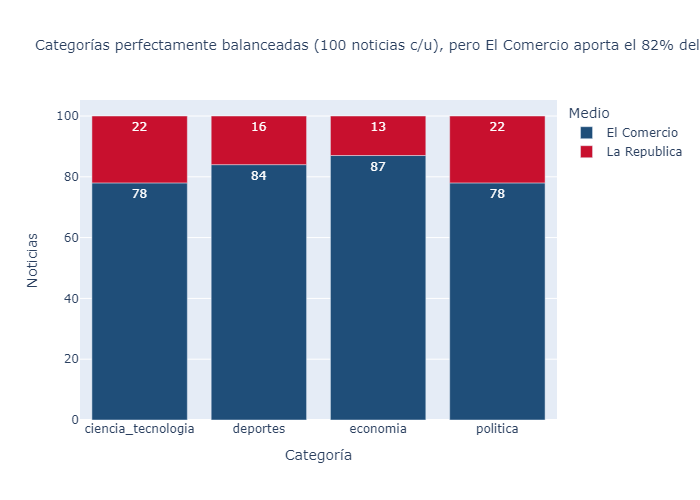

In [9]:
COLORES = {"La Republica": "#C8102E", "El Comercio": "#1F4E79"}
cat_counts = df.groupby(["etiqueta", "medio"]).size().rename("noticias").reset_index()
tot = df["etiqueta"].value_counts()
dif = tot.max() - tot.min()
pct_ec = df.medio.eq("El Comercio").mean()
balance = (f"Categorías perfectamente balanceadas ({tot.min()} noticias c/u)" if dif == 0
           else f"Categorías casi balanceadas ({tot.min()}–{tot.max()} noticias)")
titulo = f"{balance}, pero El Comercio aporta el {pct_ec:.0%} del corpus"
fig = px.bar(cat_counts, x="etiqueta", y="noticias", color="medio", color_discrete_map=COLORES, text="noticias",
             title=titulo, labels={"etiqueta": "Categoría", "noticias": "Noticias", "medio": "Medio"})
fig.update_layout(title_font_size=14)
fig.show()

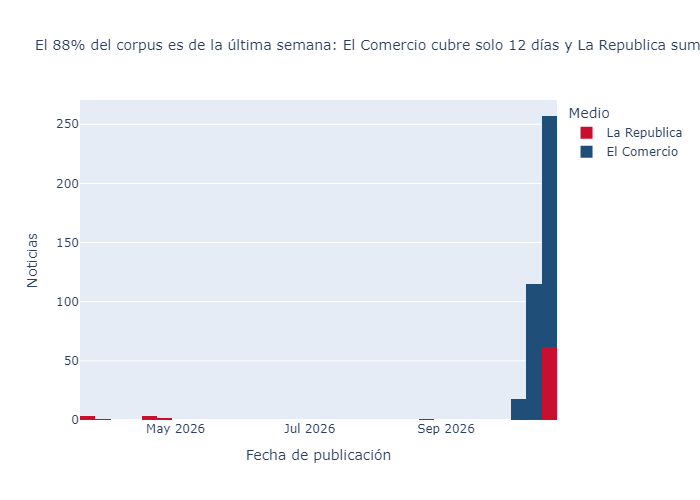

In [10]:
df["fecha_dt"] = pd.to_datetime(df["fecha"])
rangos = df.groupby("medio")["fecha_dt"].agg(["min", "max"])
dias = (rangos["max"] - rangos["min"]).dt.days
ultimos7 = (df["fecha_dt"] >= df["fecha_dt"].max() - pd.Timedelta(days=7)).mean()
amplio, estrecho = dias.idxmax(), dias.idxmin()
titulo = (f"El {ultimos7:.0%} del corpus es de la última semana: {estrecho} cubre solo {dias[estrecho]} días "
          f"y {amplio} suma algunas notas antiguas de sus portadas ({dias[amplio]} días)")
fig = px.histogram(df, x="fecha_dt", color="medio", color_discrete_map=COLORES, barmode="stack",
                   title=titulo, labels={"fecha_dt": "Fecha de publicación", "medio": "Medio"})
fig.update_layout(yaxis_title="Noticias", title_font_size=14)
fig.show()

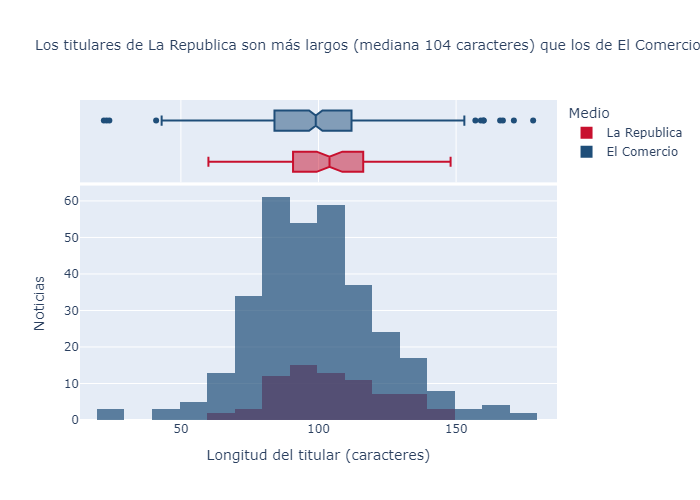

,count,mean,std,min,25%,50%,75%,max
medio,,,,,,,,
El Comercio,327.0,99.2,23.8,22.0,84.0,99.0,112.0,178.0
La Republica,73.0,104.2,19.1,60.0,91.0,104.0,116.0,148.0


In [11]:
df["largo_titular"] = df["titular"].str.len()
med = df.groupby("medio")["largo_titular"].median()
mas_largo = med.idxmax(); mas_corto = med.idxmin()
titulo = (f"Los titulares de {mas_largo} son más largos (mediana {med[mas_largo]:.0f} caracteres) "
          f"que los de {mas_corto} ({med[mas_corto]:.0f})")
fig = px.histogram(df, x="largo_titular", color="medio", color_discrete_map=COLORES, nbins=30, barmode="overlay",
                   opacity=0.7, marginal="box", title=titulo,
                   labels={"largo_titular": "Longitud del titular (caracteres)", "medio": "Medio"})
fig.update_layout(yaxis_title="Noticias", title_font_size=14)
fig.show()
df.groupby("medio")["largo_titular"].describe().round(1)

## 7. Validación: titulares más largos y más cortos

In [12]:
cols = ["largo_titular", "medio", "etiqueta", "titular"]
print("5 titulares MÁS LARGOS")
display(df.nlargest(5, "largo_titular")[cols])
print("5 titulares MÁS CORTOS")
display(df.nsmallest(5, "largo_titular")[cols])
print(f"Rango observado: {df.largo_titular.min()}–{df.largo_titular.max()} caracteres, "
      "coherente con los extremos del histograma anterior.")

5 titulares MÁS LARGOS


,largo_titular,medio,etiqueta,titular
222,178,El Comercio,deportes,"“El jugador peruano tiene un déficit grande en nutrición y táctica que resuelve a los 20 años, eso en Argentina es a..."
193,171,El Comercio,deportes,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que reconquistó a Comando Sur: Lo q...
167,167,El Comercio,deportes,“Creo que puedo llegar a un top 3 sin que nadie se quede botado”: Raúl ‘Mono’ Orlandini le responde a El Comercio so...
381,166,El Comercio,politica,"Keiko Fujimori sobre Álvaro Vargas Llosa: “Confío en que su trayectoria, experiencia y compromiso contribuirán a for..."
162,160,El Comercio,deportes,"“El día de mañana me encantaría ver a tantas niñas entrando al automovilismo”: Annia Cillóniz, líder en la categoría..."


5 titulares MÁS CORTOS


,largo_titular,medio,etiqueta,titular
281,22,El Comercio,economia,Invocación por el Perú
278,23,El Comercio,economia,AlaCena no tiene precio
280,24,El Comercio,economia,IA y Sandbox regulatorio
282,41,El Comercio,economia,La evolución de la confianza en los pagos
286,43,El Comercio,economia,Premio Nobel de Economía: la macro es micro


Rango observado: 22–178 caracteres, coherente con los extremos del histograma anterior.


Los extremos coinciden con las colas del histograma: los titulares más **cortos** son columnas de opinión de El Comercio (`economia/opinion`), con títulos tipo eslogan, mientras que los más **largos** suelen ser citas textuales entre comillas, frecuentes en entrevistas deportivas y declaraciones políticas.

## 8. Exportación de `datos/noticias.csv` (7 columnas)

In [13]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
final = df[COLUMNAS].sort_values(["medio", "etiqueta", "fecha"], ascending=[True, True, False]).reset_index(drop=True)
assert final["url"].is_unique and final["titular"].str.len().gt(0).all()
assert set(final["etiqueta"]) == {"politica", "economia", "deportes", "ciencia_tecnologia"}
final.to_csv("datos/noticias.csv", index=False, encoding="utf-8")
print("df.shape =", final.shape)
print("Bajadas vacías:", final["bajada"].eq("").sum())
print(final.groupby(["medio", "etiqueta"]).size().unstack(fill_value=0))
final.head()

df.shape = (400, 7)
Bajadas vacías: 3
etiqueta      ciencia_tecnologia  deportes  economia  politica
medio                                                         
El Comercio                   78        84        87        78
La Republica                  22        16        13        22


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Fenómeno El Niño Costero: ¿cuáles pueden ser las consecuencias para el Perú?,La coexistencia con el Fenómeno El Niño Global y el cambio climático lo hará más frecuente e intenso,El Comercio,tecnologia/actualidad,https://elcomercio.pe/tecnologia/actualidad/fenomeno-el-nino-costero-cuales-pueden-ser-las-consecuencias-para-el-per...,2026-10-18,ciencia_tecnologia
1,Intel en Latinoamérica: “Los gobiernos deben crear condiciones o reglas para un uso saludable de la IA”,João Bortone asumió la dirección de la firma estadounidense en nuestra región. Señala que “estamos en un momento atí...,El Comercio,tecnologia/actualidad,https://elcomercio.pe/tecnologia/actualidad/intel-en-latinoamerica-los-gobiernos-deben-crear-condiciones-o-reglas-pa...,2026-10-18,ciencia_tecnologia
2,Tesla presenta un Roadster capaz de ‘volar’ y en las redes sociales lo reciben con memes,El nuevo vehículo de Elon Musk combina tecnología de SpaceX. Durante las pruebas realizó varias piruetas en el aire ...,El Comercio,tecnologia/actualidad,https://elcomercio.pe/tecnologia/actualidad/tesla-presenta-un-roadster-capaz-de-volar-y-en-las-redes-sociales-lo-rec...,2026-10-18,ciencia_tecnologia
3,Padre de la IA y otros 224 científicos piden “cambios inmediatos” para su desarrollo y despliegue,"La carta abierta, que además de Yoshua Bengio incluye a especialistas en IA y ciberseguridad, remarcó incidentes don...",El Comercio,tecnologia/inteligencia-artificial,https://elcomercio.pe/tecnologia/inteligencia-artificial/padre-de-la-ia-y-otros-224-cientificos-piden-cambios-inmedi...,2026-10-18,ciencia_tecnologia
4,Millones de personas podrían tener que abandonar sus hogares por el cambio climático en el sudeste asiático,"El auento del nivel del mar, las inundaciones y las sequías amenazan hogares y tierras de cultivo",El Comercio,tecnologia/actualidad,https://elcomercio.pe/tecnologia/actualidad/millones-de-personas-podrian-tener-que-abandonar-sus-hogares-por-el-camb...,2026-10-17,ciencia_tecnologia


In [14]:
# Verificación de que las URLs funcionan: muestra aleatoria de 10 (HEAD, con pausa)
muestra = final.sample(10, random_state=42)
estados = []
for u in muestra["url"]:
    try:
        estados.append(session.head(u, timeout=20, allow_redirects=True).status_code)
    except requests.RequestException as e:
        estados.append(type(e).__name__)
    time.sleep(PAUSA)
muestra.assign(http=estados)[["medio", "url", "http"]]

,medio,url,http
209,El Comercio,https://elcomercio.pe/economia/peru/gobierno-destina-mas-de-s16-millones-para-financiar-subsidio-a-mototaxistas-de-t...,200
280,El Comercio,https://elcomercio.pe/politica/gobierno/keiko-fujimori-sobre-incidentes-en-comision-de-constitucion-por-delegacion-d...,200
33,El Comercio,https://elcomercio.pe/tecnologia/gadgets/google-lanza-fitbit-edge-una-pulsera-avanzada-de-salud-con-bateria-para-una...,200
210,El Comercio,https://elcomercio.pe/economia/peru/iata-endurece-posicion-por-caida-de-conexiones-en-lima-lap-intenta-desviar-la-re...,200
93,El Comercio,https://elcomercio.pe/deporte-total/futbol-peruano/alianza-lima-el-furioso-que-se-dedique-a-administrar-de-pablo-gue...,200
84,El Comercio,https://elcomercio.pe/deporte-total/espana/donde-ver-real-madrid-vs-sevilla-en-vivo-gratis-por-laliga-a-que-hora-jue...,200
329,La Republica,https://larepublica.pe/ciencia/2026/10/18/en-1993-se-liberaron-300-bisontes-en-una-pradera-de-oklahoma-y-ahora-deamb...,200
94,El Comercio,https://elcomercio.pe/deporte-total/futbol-peruano/alianza-lima-vs-atletico-grau-en-vivo-online-gratis-por-torneo-cl...,200
266,El Comercio,https://elcomercio.pe/politica/gobierno/el-proyecto-de-ley-mape-del-gobierno-desde-la-fiscalizacion-a-las-plantas-al...,200
126,El Comercio,https://elcomercio.pe/deporte-total/caminos-del-inca-2026-raul-mono-orlandini-creo-que-puedo-llegar-a-un-top-3-sin-q...,200


## Conclusiones de la Parte 1
* Se construyó un corpus comparado con titulares y bajadas reales de **La República** y **El Comercio** usando únicamente canales permitidos por `robots.txt` (RSS, sitemaps y portadas de sección sin paginar).
* Las categorías quedaron balanceadas gracias a que El Comercio completa lo que La República no expone; el desbalance **por medio** es la principal limitación (ver README).
* Las noticias de secciones como sociedad, mundo, espectáculos u opinión se descartaron explícitamente en lugar de crear una quinta categoría.